<a href="https://colab.research.google.com/github/SMOULD07/-CLIP_with_medical_images/blob/main/CLIP_tutorial_ROCO_and_fine_tunig.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Notebook created in 2024 with the help of Xiaoyang Wei, Phd student at LIPADE, Université Paris Cité

# Interacting with CLIP

This is a self-contained notebook that shows how to download and run CLIP models, calculate the similarity between arbitrary image and text inputs, and perform zero-shot image classifications.

# Preparation for Colab

Make sure you're running a GPU runtime; if not, select "GPU" as the hardware accelerator in Runtime > Change Runtime Type in the menu. The next cells will install the `clip` package and its dependencies, and check if PyTorch 1.7.1 or later is installed.

In [ ]:
! pip install ftfy regex tqdm
! pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-zw3i5px9
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-zw3i5px9
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369548 sha256=b5ec7592459981a007e8441e3bbfcc6428f2fae378f8a189b38b5b79af5f668f
  Stored in directory: /tmp/pip-ephem-wheel-cache-_4lzwei_/wheels/cb/a8/74/5f32d6cf0407457f0f62737b6da5c14eb86b9cac476fdf630d
Successfully built clip


# Loading the model

`clip.available_models()` will list the names of available CLIP models.

In [ ]:
import clip
import numpy as np

clip.available_models()

['RN50',
 'RN101',
 'RN50x4',
 'RN50x16',
 'RN50x64',
 'ViT-B/32',
 'ViT-B/16',
 'ViT-L/14',
 'ViT-L/14@336px']

In [ ]:
model, preprocess = clip.load("ViT-B/16")
model.cuda().eval()
input_resolution = model.visual.input_resolution
context_length = model.context_length
vocab_size = model.vocab_size

print("Model parameters:", f"{np.sum([int(np.prod(p.shape)) for p in model.parameters()]):,}")
print("Input resolution:", input_resolution)
print("Context length:", context_length)
print("Vocab size:", vocab_size)

100%|████████████████████████████████████████| 335M/335M [00:01<00:00, 262MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Model parameters: 149,620,737
Input resolution: 224
Context length: 77
Vocab size: 49408


# Image Preprocessing

We resize the input images and center-crop them to conform with the image resolution that the model expects. Before doing so, we will normalize the pixel intensity using the dataset mean and standard deviation.

The second return value from `clip.load()` contains a torchvision `Transform` that performs this preprocessing.



In [ ]:
preprocess

Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7d232f179d00>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)

# Text Preprocessing

We use a case-insensitive tokenizer, which can be invoked using `clip.tokenize()`. By default, the outputs are padded to become 77 tokens long, which is what the CLIP models expects.

In [ ]:
clip.tokenize("Hello World!")

tensor([[49406,  3306,  1002,   256, 49407,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0]], dtype=torch.int32)

# Setting up input images and texts

We are going to feed 8 example natrural/medical images and their textual descriptions to the model, and compare the similarity between the corresponding features.

The tokenizer is case-insensitive, and we can freely give any suitable textual descriptions.

In [ ]:
import os
import skimage
import IPython.display
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from collections import OrderedDict
import torch

%matplotlib inline
%config InlineBackend.figure_format = 'retina'


# to mount google drive
if os.getcwd()=='/content':
    try:
        from google.colab import drive
        base_working_dir = '/content/drive/MyDrive'
        drive.mount('/content/drive')
    except:
        base_working_dir = os.getcwd()
        pass
!mkdir -p drive
!google-drive-ocamlfuse drive
print(base_working_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/bin/bash: line 1: google-drive-ocamlfuse: command not found
/content/drive/MyDrive


In [ ]:
# images to use and their textual descriptions
descriptions = {
    "page": "a page of text about segmentation",
    "chelsea": "a facial photo of a tabby cat",
    "astronaut": "a portrait of an astronaut with the American flag",
    "rocket": "a rocket standing on a launchpad",
    "motorcycle_right": "a red motorcycle standing in a garage",
    "camera": "a person looking at a camera on a tripod",
    "horse": "a black-and-white silhouette of a horse",
    "coffee": "a cup of coffee on a saucer"
}

med_descriptions = {
    "ROCO_00002": "CT scan in axial view showing obliteration of the left maxillary sinus",
    "ROCO_00017": "Coronary angiogram demonstrating occluded arteries",
    "ROCO_00028": "T2 weighted MRI image showing foraminal extensions of the cysts",
    "ROCO_00033": "Lytic lesions (arrows) involving the humerus.",
    "ROCO_00050": "Free air beneath the diaphragm at abdominal x-ray film",
    "ROCO_00056": "View of giant cell tumor of thumb metacarpal preoperatively",
    "ROCO_00060": "Transverse view of lung using CT.Leukemic infiltration is seen.",
    "ROCO_00135": "CT scan showing multiple non-communicating cysts in liver and kidney"
}

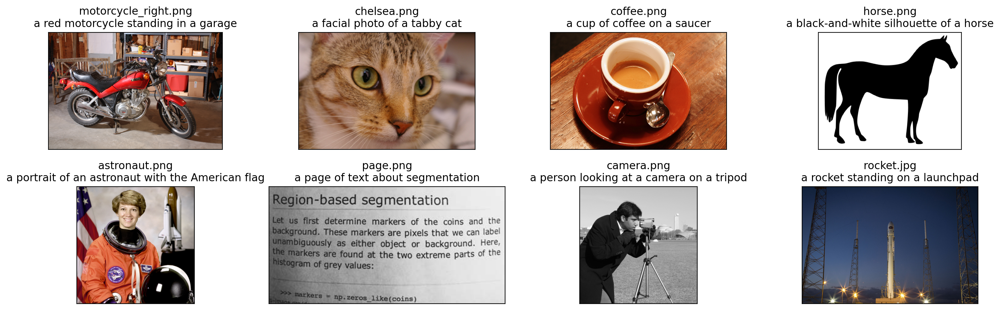

In [ ]:
original_images = []
images = []
texts = []
plt.figure(figsize=(16, 5))

skimage.data.download_all(directory=None)
for filename in [filename for filename in os.listdir(skimage.data_dir) if filename.endswith(".png") or filename.endswith(".jpg")]:
    name = os.path.splitext(filename)[0]
    if name not in descriptions:
        continue

    image = Image.open(os.path.join(skimage.data_dir, filename)).convert("RGB")

    plt.subplot(2, 4, len(images) + 1)
    plt.imshow(image)
    plt.title(f"{filename}\n{descriptions[name]}")
    plt.xticks([])
    plt.yticks([])

    original_images.append(image)
    images.append(preprocess(image))
    texts.append(descriptions[name])

plt.tight_layout()


## Building features

We normalize the images, tokenize each text input, and run the forward pass of the model to get the image and text features.

In [ ]:
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()

## Calculating cosine similarity

We normalize the features and calculate the dot product of each pair.

Text(0.5, 1.0, 'Cosine similarity between text and image features(natural)')

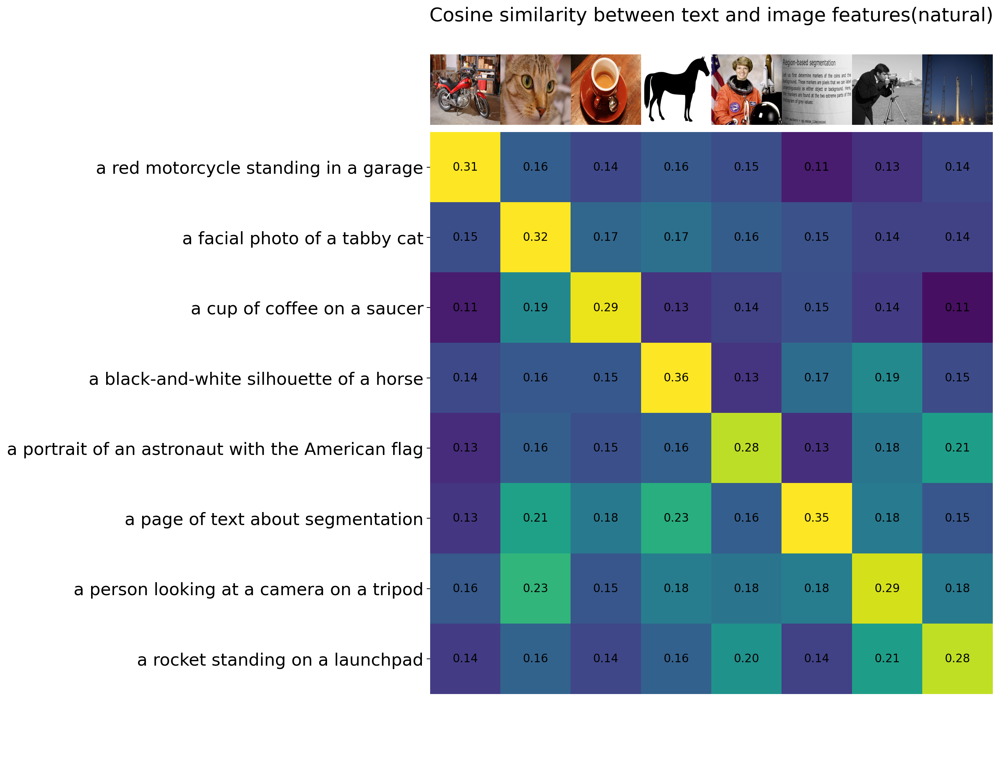

In [ ]:
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
# plt.colorbar()
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(natural)", size=20)

## Performance of CLIP in medical domain

Text(0.5, 1.0, 'Cosine similarity between text and image features(medical)')

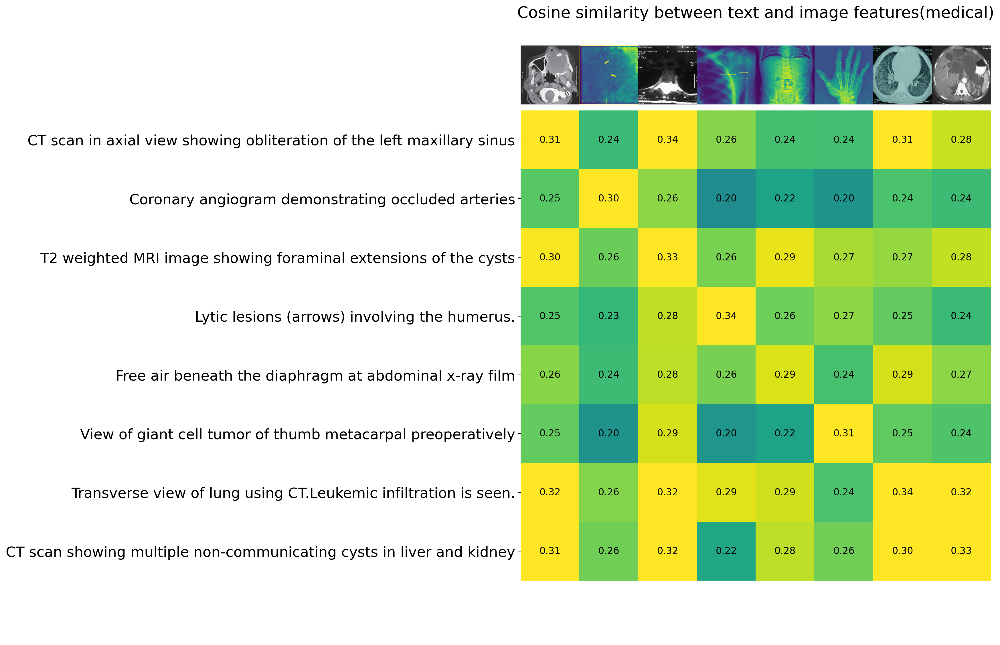

In [ ]:
original_images = []
images = []
texts = []
for filename in list(med_descriptions.keys()):
    image = Image.open(os.path.join("/content/drive/MyDrive/data/pretrain_data/roco/train/radiology/images", filename+'.jpg'))
    original_images.append(image)
    images.append(preprocess(image))
    texts.append(med_descriptions[filename])
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
# plt.colorbar()
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)
for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(medical)", size=20)


# Zero-Shot Image Classification

You can classify images using the cosine similarity (times 100) as the logits to the softmax operation.

In [ ]:
from torchvision.datasets import CIFAR100

cifar100 = CIFAR100(os.path.expanduser("~/.cache"), transform=preprocess, download=True)

100%|██████████| 169M/169M [19:36<00:00, 144kB/s]


In [ ]:
text_descriptions = [f"This is a photo of a {label}" for label in cifar100.classes]
text_tokens = clip.tokenize(text_descriptions).cuda()

In [ ]:
with torch.no_grad():
    text_features = model.encode_text(text_tokens).float()
    text_features /= text_features.norm(dim=-1, keepdim=True)

text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)
top_probs, top_labels = text_probs.cpu().topk(5, dim=-1)

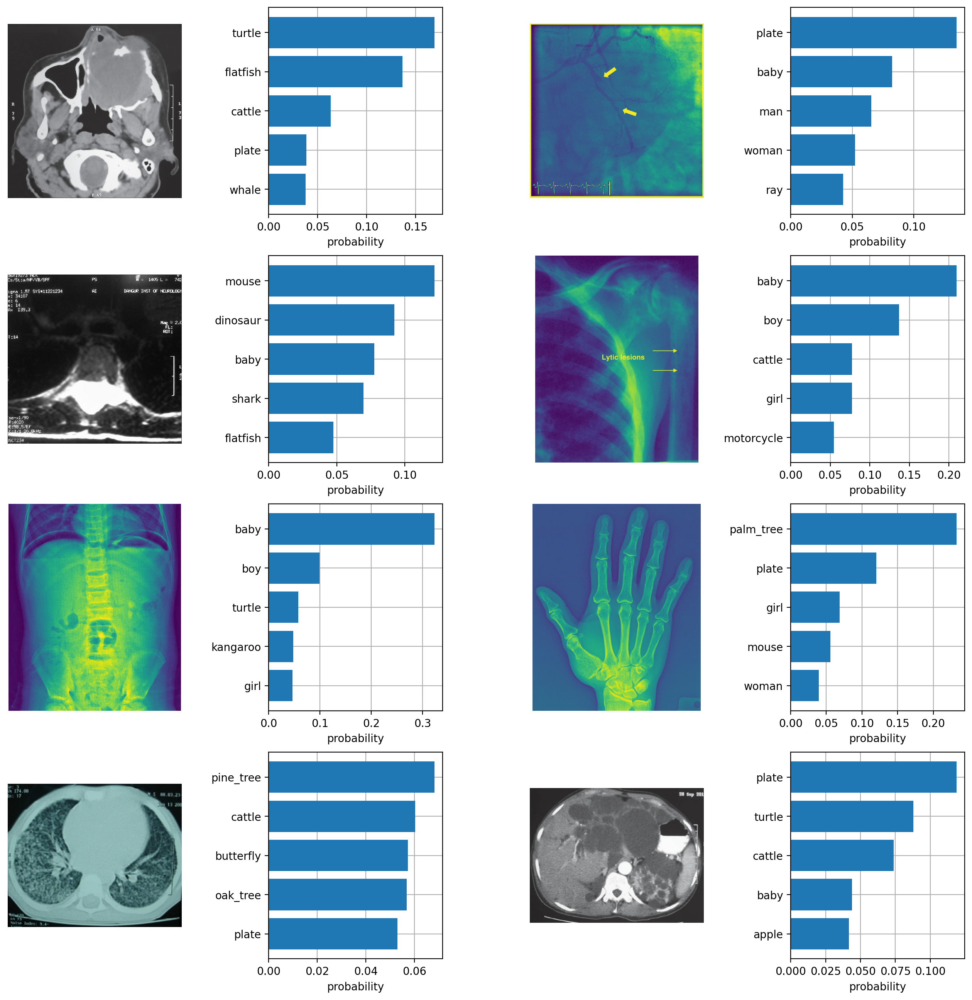

In [ ]:
plt.figure(figsize=(16, 16))

for i, image in enumerate(original_images):
    plt.subplot(4, 4, 2 * i + 1)
    plt.imshow(image)
    plt.axis("off")

    plt.subplot(4, 4, 2 * i + 2)
    y = np.arange(top_probs.shape[-1])
    plt.grid()
    plt.barh(y, top_probs[i])
    plt.gca().invert_yaxis()
    plt.gca().set_axisbelow(True)
    plt.yticks(y, [cifar100.classes[index] for index in top_labels[i].numpy()])
    plt.xlabel("probability")

plt.subplots_adjust(wspace=0.5)
plt.show()

# Fine-tuning CLIP on ROCO



In [ ]:
# dataset location
csv_file ="/content/drive/My Drive/data/roco-list.csv"
root_dir = "/content/drive/My Drive/data/pretrain_data/roco/train/radiology/images"
val_csv_file = "/content/drive/My Drive/data/local-val-list.csv"
val_root_dir = "/content/drive/My Drive/data/pretrain_data/roco/val/radiology/images"

# train options
seed = 42
batch_size = 16
image_size = 224
start_epoch = 0
epochs = 10
visual_encoder = "clip@ViT-B/16"
learning_rate = 3e-6
model_path = "/content/drive/My Drive/model_checkpoint_CLIP_ROCO"


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torchvision
import datetime
import time
from tqdm import tqdm
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
from torch.utils.data import Dataset
import random
import clip



class CLRDataset(Dataset):
    """Contrastive Learning Representations Dataset."""

    def __init__(self, csv_file, root_dir, transform=None, clip=False):
        self.clr_frame = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform
        self.clip = clip

    def __len__(self):
        return len(self.clr_frame)

    def text_sampling(self, text):
        text = text.replace("\n", " ")
        text = text.split(".")
        if '' in text:
            text.remove('')
        text = random.choice(text)
        return text

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        img_name = os.path.join(self.root_dir,
                                self.clr_frame.iloc[idx, 0]
                                )
        if not os.path.exists(img_name):
            img_name=img_name.replace('train','val')
        image = Image.open(img_name)
        if not self.clip:
            image = image.convert('RGB')
        text = self.clr_frame.iloc[idx, 1]
        name = self.clr_frame.iloc[idx, 0]
        sample = {'image': image, 'text': text,'name':name}
        if self.clip:
            sample = self.transform(sample['image']), sample['text'],sample['name'] #self.text_sampling(sample['text'])
        elif self.transform:
            sample = self.transform(sample)

        return sample


def load_optimizer( model, lr=3e-6):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, epochs, eta_min=0, last_epoch=-1
    )
    return optimizer, scheduler


def train( train_loader, model, tokenizer, optimizer,truncation):
    loss_epoch = 0
    for step, (images, texts,name) in enumerate(train_loader):
        optimizer.zero_grad()
        x_v = images.to('cuda')
        x_u = tokenizer(list(texts), truncate=True).to('cuda')

        v,u=model(x_v,x_u)

        labels = torch.arange(batch_size, dtype=torch.long, device='cuda')

        loss_img = torch.nn.CrossEntropyLoss()
        loss_txt = torch.nn.CrossEntropyLoss()

        img_loss = loss_img(v,labels)
        text_loss = loss_txt(u,labels)

        loss = (img_loss + text_loss)/2

        loss.backward()
        optimizer.step()

        if step % 500 == 0:
            print(f"Step [{step}/{len(train_loader)}]\t Loss: {loss.item()}")

        loss_epoch += loss.item()
    return loss_epoch



def validate( val_loader, model, tokenizer, optimizer, truncation):

    with torch.no_grad():
        model.eval()
        loss_epoch = 0
        for step, (x_v, x_u, _) in enumerate(val_loader):  # CORRIGÉ : le dataset renvoie (image, texte, nom)
            x_v = x_v.to('cuda')
            x_u = tokenizer(list(x_u), truncate=True).to('cuda')

            v,u=model(x_v,x_u)

            labels = torch.arange(batch_size, dtype=torch.long, device='cuda')

            loss_img = torch.nn.CrossEntropyLoss()
            loss_txt = torch.nn.CrossEntropyLoss()

            img_loss = loss_img(v,labels)
            text_loss = loss_txt(u,labels)

            loss = (img_loss + text_loss)/2
            loss_epoch += loss.item()

    model.train()
    return loss_epoch

def main(gpu):

    is_master=True

    # set GPU device
    torch.cuda.set_device(gpu)
    torch.manual_seed(seed)
    np.random.seed(seed)

    # initialize model
    print("Initializing model... ", end="", flush=True)
    model, preprocess = clip.load(visual_encoder.split("@")[-1], device='cuda', jit=False)
    model.float()
    tokenizer=clip.tokenize
    train_fonction = train
    validate_fonction = validate

    # optimizer
    optimizer, scheduler = load_optimizer(model, lr=float(learning_rate))

    # initialize dataloader
    transform = preprocess
    print('Image_Transform',transform)
    train_dataset = CLRDataset(csv_file=csv_file,
                               root_dir=root_dir,
                               transform=transform,
                               clip = True
                               )

    val_dataset = CLRDataset(csv_file=val_csv_file,
                             root_dir=val_root_dir,
                             transform=transform,
                             clip = True
                             )

    train_sampler = None
    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=(train_sampler is None),
        drop_last=True,
        num_workers=8,
        sampler=train_sampler,
    )

    val_loader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        drop_last=True,
        num_workers=8
    )

    print("[DONE]\n")
    print("STARTING TRAINING")
    print('Start Time =', datetime.datetime.now().strftime("%H:%M:%S"), '\n')

    t0 = time.time()
    global_step = 0
    current_epoch = 0
    best_val_loss = np.inf

    for epoch in range(0, epochs):
        if epoch<2:
            if train_sampler is not None:
                train_sampler.set_epoch(epoch)

            lr = optimizer.param_groups[0]["lr"]
            loss_epoch = train_fonction(train_loader, model, tokenizer, optimizer,True)

        if is_master:
            val_loss = validate_fonction( val_loader, model, tokenizer, optimizer, True)
            if val_loss < best_val_loss:
                torch.save(model.state_dict(), os.path.join(model_path, "best_checkpoint.pth"))
                best_val_loss = val_loss

            epoch_counter = epoch - 0
            elapsed = time.time() - t0
            epoch_time = elapsed/(epoch_counter+1)
            remaining = (epochs - (epoch_counter+1))*epoch_time
            remaining = str(datetime.timedelta(seconds=round(remaining)))
            elapsed = str(datetime.timedelta(seconds=round(elapsed)))
            print(f'Epoch {epoch_counter+1}/{epochs} [{elapsed}<{remaining}, {round(epoch_time, 2)}s/epoch] {round((epoch_counter+1)/epochs*100, 1)}% loss: {loss_epoch / len(train_loader)}\t val_loss: {val_loss / len(val_loader)} lr: {lr}')

            current_epoch += 1


In [ ]:
if not os.path.exists(model_path):
    os.makedirs(model_path)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)
main(0)

Device: cuda:0
Initializing model... 

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Image_Transform Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7d232f179d00>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)
[DONE]

STARTING TRAINING
Start Time = 21:21:45 



/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Step [0/4087]	 Loss: 1.6037722826004028


KeyboardInterrupt: 

## Performance of CLIP in medical domain(after fine-tuning on ROCO )

Text(0.5, 1.0, 'Cosine similarity between text and image features(medical)')

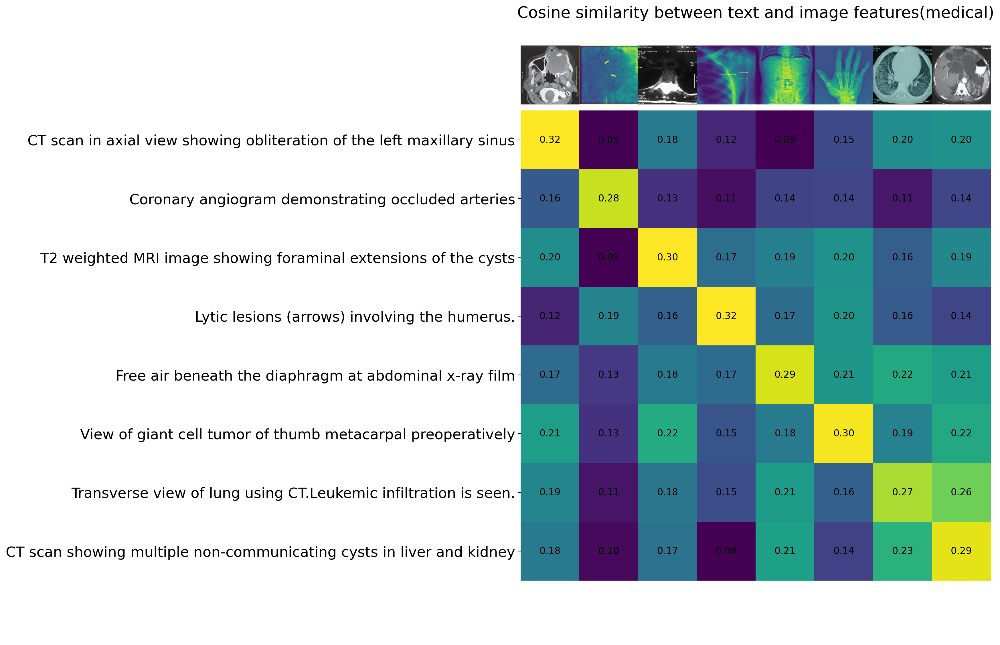

In [ ]:
#load checkpoint
model.load_state_dict(torch.load('/content/drive/My Drive/data/ViT-B-16_best_checkpoint_2.tar'))

#compute txt-img similarity again
original_images = []
images = []
texts = []
for filename in list(med_descriptions.keys()):
    image = Image.open(os.path.join(root_dir, filename+'.jpg'))
    original_images.append(image)
    images.append(preprocess(image))
    texts.append(med_descriptions[filename])
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(medical)", size=20)

# Question 2 : tester different model valables et evaluation entre eux

In [ ]:
# modeles disponible
clip.available_models()

['RN50',
 'RN101',
 'RN50x4',
 'RN50x16',
 'RN50x64',
 'ViT-B/32',
 'ViT-B/16',
 'ViT-L/14',
 'ViT-L/14@336px']

In [ ]:
# Modele Vit-B/32
model_b32, preprocess_b32 = clip.load("ViT-B/32")
model_b32.cuda().eval()
input_resolution = model_b32.visual.input_resolution
context_length = model_b32.context_length
vocab_size = model_b32.vocab_size

print("Model parameters:", f"{np.sum([int(np.prod(p.shape)) for p in model_b32.parameters()]):,}")
print("Input resolution:", input_resolution)
print("Context length:", context_length)
print("Vocab size:", vocab_size)

100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 213MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Model parameters: 151,277,313
Input resolution: 224
Context length: 77
Vocab size: 49408


In [ ]:
# modele Vit-L/14
model_l14, preprocess_l14 = clip.load("ViT-L/14")
model_l14.cuda().eval()
input_resolution = model_l14.visual.input_resolution
context_length = model_l14.context_length
vocab_size = model_l14.vocab_size

print("Model parameters:", f"{np.sum([int(np.prod(p.shape)) for p in model_l14.parameters()]):,}")
print("Input resolution:", input_resolution)
print("Context length:", context_length)
print("Vocab size:", vocab_size)

100%|████████████████████████████████████████| 890M/890M [00:06<00:00, 140MiB/s]


Model parameters: 427,616,513
Input resolution: 224
Context length: 77
Vocab size: 49408


In [ ]:
# modele RN50
model_rn50, preprocess_rn50 = clip.load("RN50")
model_rn50.cuda().eval()
input_resolution = model_rn50.visual.input_resolution
context_length = model_rn50.context_length
vocab_size = model_rn50.vocab_size

print("Model parameters:", f"{np.sum([int(np.prod(p.shape)) for p in model_rn50.parameters()]):,}")
print("Input resolution:", input_resolution)
print("Context length:", context_length)
print("Vocab size:", vocab_size)

100%|████████████████████████████████████████| 244M/244M [00:01<00:00, 223MiB/s]


Model parameters: 102,007,137
Input resolution: 224
Context length: 77
Vocab size: 49408


## Question 2: évaluation quantitative sur le test de ROCO

Protocole identique pour tous les modèles : même sous-ensemble fixe du **test** de ROCO, même taille de batch.
Pour chaque batch, chaque image doit retrouver sa propre légende parmi celles du batch
Métriques utilisées sont : loss contrastive, accuracy top-1 / top-5, temps d'inférence, nombre de paramètres.

In [ ]:
import glob
import time
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

DATA_DIR = "/content/drive/My Drive/data"
TEST_DIR = "/content/drive/MyDrive/data/pretrain_data/roco/test/radiology/images"
TEST_RADIOLOGY_DIR = os.path.dirname(TEST_DIR)
N_TEST = 640         # sous-ensemble fixe du test
EVAL_BATCH_SIZE = 64   # même taille de batch pour tous les modèles

test_files = set(os.listdir(TEST_DIR))
print("Images de test trouvées :", len(test_files))


def read_caption_file(path):
    if path.endswith(".csv"):
        return pd.read_csv(path)
    return pd.read_csv(path, sep="\t", header=None, quoting=3)


def build_test_pairs(df, files):
    """Retrouve la colonne des noms d'images et celle des légendes."""
    best_col, best_names, best_hits = None, None, 0
    for col in df.columns:
        names = df[col].astype(str).str.strip()
        names = names.where(names.str.lower().str.endswith(".jpg"), names + ".jpg")
        hits = names.isin(files).sum()
        if hits > best_hits:
            best_col, best_names, best_hits = col, names, hits
    other_cols = [c for c in df.columns if c != best_col]
    if best_hits == 0 or not other_cols:
        return None
    cap_col = max(other_cols, key=lambda c: df[c].astype(str).str.len().mean())
    pairs = pd.DataFrame({"name": best_names, "caption": df[cap_col].astype(str).str.strip()})
    pairs = pairs[pairs["name"].isin(files) & (pairs["caption"].str.len() > 0)]
    return pairs.drop_duplicates("name").reset_index(drop=True)


candidates = (sorted(glob.glob(os.path.join(DATA_DIR, "*test*.csv")))
              + sorted(glob.glob(os.path.join(TEST_RADIOLOGY_DIR, "*.csv")))
              + sorted(glob.glob(os.path.join(TEST_RADIOLOGY_DIR, "*.txt"))))
test_pairs = None
for path in candidates:
    try:
        pairs = build_test_pairs(read_caption_file(path), test_files)
    except Exception as e:
        print("Ignoré :", path, "->", e)
        continue
    if pairs is not None and len(pairs) > 0:
        test_pairs = pairs
        print(f"Légendes de test lues dans : {path} ({len(pairs)} paires image/légende)")
        break

if test_pairs is None:
    print("Fichiers dans", DATA_DIR, ":", os.listdir(DATA_DIR))
    print("Fichiers dans", TEST_RADIOLOGY_DIR, ":", os.listdir(TEST_RADIOLOGY_DIR))
    raise FileNotFoundError("Aucun fichier de légendes de test trouvé : regarder les fichiers listés ci-dessus.")

if N_TEST is not None and len(test_pairs) > N_TEST:
    test_pairs = test_pairs.sample(n=N_TEST, random_state=42).reset_index(drop=True)
test_csv = "/content/roco_test_subset.csv"
test_pairs.to_csv(test_csv, index=False)

# RN50, ViT-B/32, ViT-B/16 et ViT-L/14 utilisent tous la même résolution 224 et le même prétraitement
# on lit les images une seule fois depuis Drive et on les garde en mémoire pour tous les modèles

test_dataset = CLRDataset(csv_file=test_csv, root_dir=TEST_DIR, transform=preprocess, clip=True)
cache_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2)
cached_images, cached_captions, cached_names = [], [], []
for imgs, caps, names in tqdm(cache_loader, desc="Lecture des images de test"):
    cached_images.append(imgs.half())
    cached_captions += list(caps)
    cached_names += list(names)
cached_images = torch.cat(cached_images)


class CachedROCO(Dataset):
    def __len__(self):
        return len(cached_captions)

    def __getitem__(self, i):
        return cached_images[i], cached_captions[i], cached_names[i]


roco_test_loader = DataLoader(CachedROCO(), batch_size=EVAL_BATCH_SIZE, shuffle=False, drop_last=True)
print("Paires de test évaluées :", len(roco_test_loader) * EVAL_BATCH_SIZE)

Images de test trouvées : 8179
Légendes de test lues dans : /content/drive/MyDrive/data/pretrain_data/roco/test/radiology/captions.txt (8179 paires image/légende)


Lecture des images de test: 100%|██████████| 10/10 [00:05<00:00,  1.78it/s]

Paires de test évaluées : 640


In [ ]:
def test(test_loader, model, tokenizer, truncation):

  cross_entropy_loss = torch.nn.CrossEntropyLoss()
  top1_results = 0
  top5_results = 0
  total = 0

  with torch.inference_mode():
    test_loss = []
    model.eval()
    for step, (x_v, x_u, _) in enumerate(test_loader):
      x_v = x_v.to("cuda")
      x_u = tokenizer(list(x_u), truncate=truncation).to("cuda")

      v,u = model(x_v, x_u)

      labels = torch.arange(x_v.size(0), dtype=torch.long, device="cuda")

      # top 1
      top1 = v.argmax(dim=-1)
      top1_results += (top1 == labels).sum().item()

      # top 5
      top5 = v.topk(min(5, x_v.size(0)), dim=1).indices
      top5_results += (top5 == labels.unsqueeze(1)).any(dim=1).sum().item()

      img_loss = cross_entropy_loss(v, labels)
      text_loss = cross_entropy_loss(u, labels)

      loss = (img_loss + text_loss) / 2
      test_loss.append(loss.item())

      total += x_v.size(0)



  return [np.mean(test_loss), 100 * top1_results/total, 100 * top5_results/total]

In [ ]:
# ViT-B/16 pré-entraîné
model_b16, preprocess_b16 = clip.load("ViT-B/16")
model_b16.cuda().eval()

FINETUNED_CHECKPOINT = "/content/drive/My Drive/data/ViT-B-16_best_checkpoint_2.tar"
model_b16_ft = None
if os.path.exists(FINETUNED_CHECKPOINT):
    model_b16_ft, _ = clip.load("ViT-B/16")
    model_b16_ft.load_state_dict(torch.load(FINETUNED_CHECKPOINT, map_location="cuda"))
    model_b16_ft.cuda().eval()
else:
    print("Checkpoint fine-tuné introuvable : comparaison sans le modèle fine-tuné.")

models_to_compare = {
    "RN50": model_rn50,
    "ViT-B/32": model_b32,
    "ViT-B/16": model_b16,
    "ViT-L/14": model_l14,
}
if model_b16_ft is not None:
    models_to_compare["ViT-B/16 fine-tuné ROCO"] = model_b16_ft

for name, m in models_to_compare.items():
    assert m.visual.input_resolution == 224, f"{name} n'utilise pas des images 224x224"

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


In [ ]:
rows = []
for name, m in models_to_compare.items():
    torch.cuda.synchronize()
    t0 = time.time()
    loss, top1, top5 = test(roco_test_loader, m, clip.tokenize, True)
    torch.cuda.synchronize()
    rows.append({
        "Modèle": name,
        "Paramètres (M)": round(sum(p.numel() for p in m.parameters()) / 1e6, 1),
        "Loss test": round(loss, 3),
        "Top-1 (%)": round(top1, 2),
        "Top-5 (%)": round(top5, 2),
        "Temps (s)": round(time.time() - t0, 1),
    })
    print(rows[-1])

results_q2 = pd.DataFrame(rows)
print(f"\nHasard : top-1 = {100 / EVAL_BATCH_SIZE:.2f} %, top-5 = {500 / EVAL_BATCH_SIZE:.2f} % (batch de {EVAL_BATCH_SIZE})")
results_q2

{'Modèle': 'RN50', 'Paramètres (M)': 102.0, 'Loss test': np.float64(3.279), 'Top-1 (%)': 19.22, 'Top-5 (%)': 51.56, 'Temps (s)': 2.7}
{'Modèle': 'ViT-B/32', 'Paramètres (M)': 151.3, 'Loss test': np.float64(3.062), 'Top-1 (%)': 23.44, 'Top-5 (%)': 55.0, 'Temps (s)': 1.1}
{'Modèle': 'ViT-B/16', 'Paramètres (M)': 149.6, 'Loss test': np.float64(2.897), 'Top-1 (%)': 26.41, 'Top-5 (%)': 61.25, 'Temps (s)': 2.4}
{'Modèle': 'ViT-L/14', 'Paramètres (M)': 427.6, 'Loss test': np.float64(2.45), 'Top-1 (%)': 35.94, 'Top-5 (%)': 74.38, 'Temps (s)': 8.3}
{'Modèle': 'ViT-B/16 fine-tuné ROCO', 'Paramètres (M)': 149.6, 'Loss test': np.float64(1.05), 'Top-1 (%)': 63.28, 'Top-5 (%)': 95.62, 'Temps (s)': 2.5}

Hasard : top-1 = 1.56 %, top-5 = 7.81 % (batch de 64)


,Modèle,Paramètres (M),Loss test,Top-1 (%),Top-5 (%),Temps (s)
0,RN50,102.0,3.279,19.22,51.56,2.7
1,ViT-B/32,151.3,3.062,23.44,55.00,1.1
2,ViT-B/16,149.6,2.897,26.41,61.25,2.4
3,ViT-L/14,427.6,2.450,35.94,74.38,8.3
4,ViT-B/16 fine-tuné ROCO,149.6,1.050,63.28,95.62,2.5


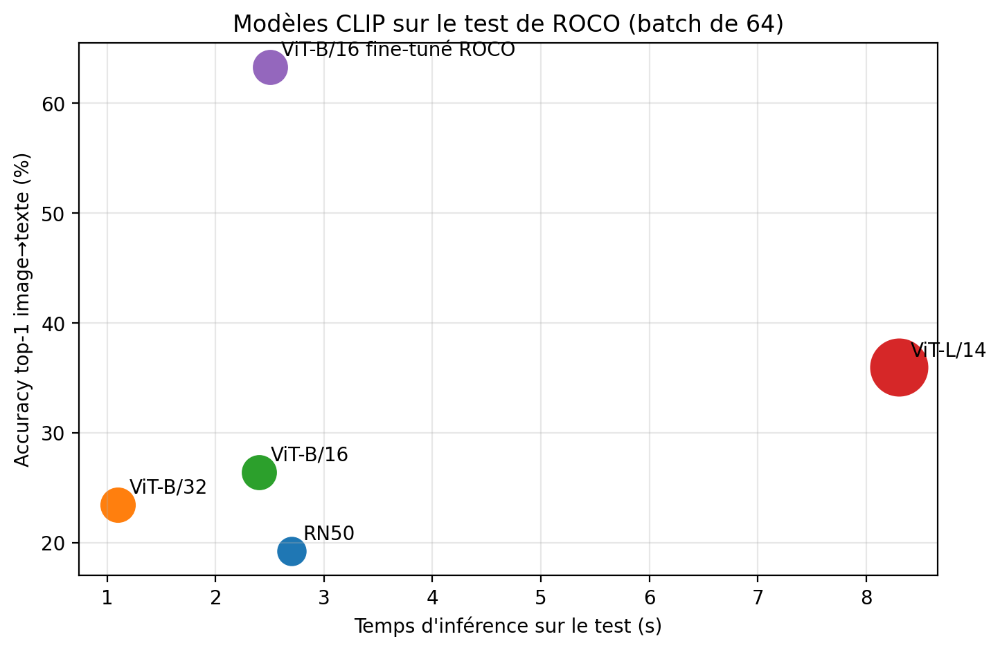

In [ ]:
plt.figure(figsize=(8, 5))
for _, r in results_q2.iterrows():
    plt.scatter(r["Temps (s)"], r["Top-1 (%)"], s=r["Paramètres (M)"] * 2)
    plt.annotate(r["Modèle"], (r["Temps (s)"], r["Top-1 (%)"]), textcoords="offset points", xytext=(6, 6))
plt.xlabel("Temps d'inférence sur le test (s)")
plt.ylabel("Accuracy top-1 image→texte (%)")
plt.title(f"Modèles CLIP sur le test de ROCO (batch de {EVAL_BATCH_SIZE})")
plt.grid(alpha=0.3)
plt.show()

# Question 3 : Montrer les resultats sur les données de test du jeu de données medicale

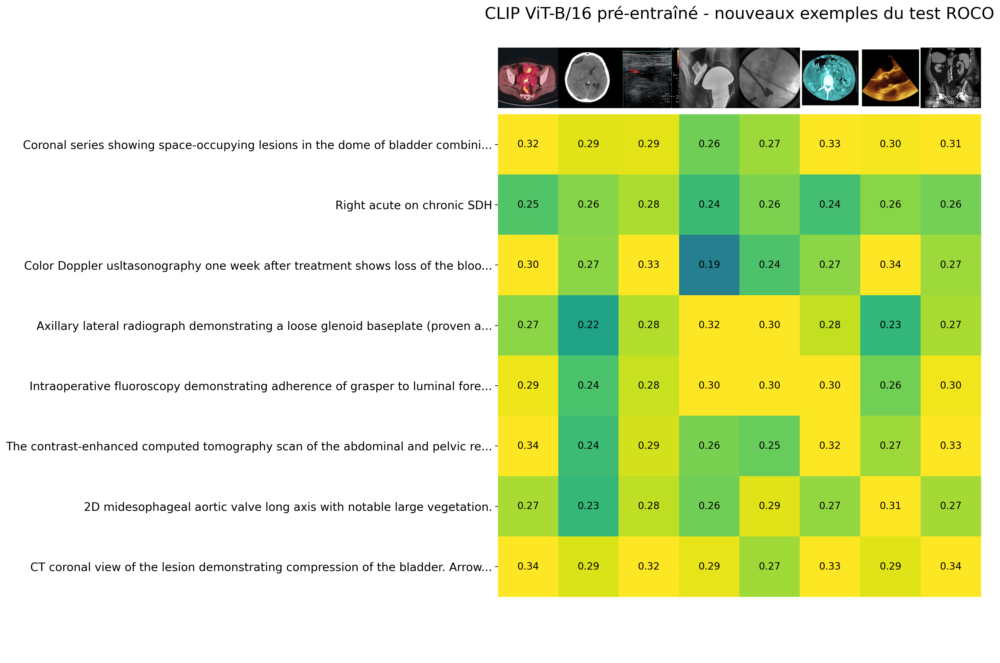

CLIP ViT-B/16 pré-entraîné : 3/8 images associées à leur bonne légende


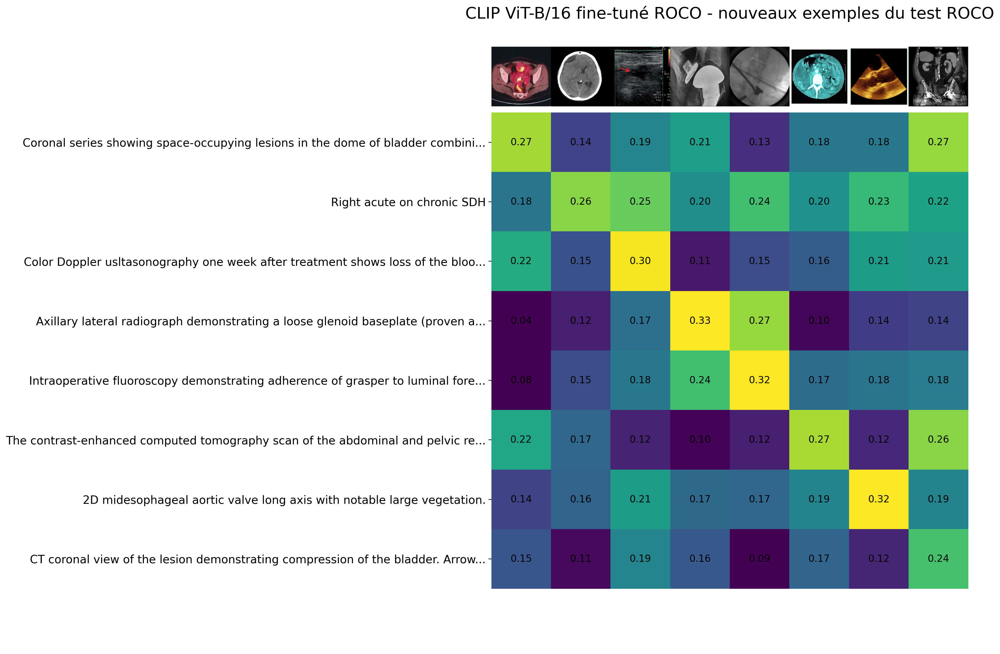

CLIP ViT-B/16 fine-tuné ROCO : 7/8 images associées à leur bonne légende


In [ ]:
rng = np.random.default_rng(0)
q3_idx = rng.choice(len(cached_captions), size=8, replace=False)
q3_names = [cached_names[i] for i in q3_idx]
q3_texts = [cached_captions[i].replace("\n", " ").strip() for i in q3_idx]
q3_display = [Image.open(os.path.join(TEST_DIR, n)).convert("RGB") for n in q3_names]


def short_caption(c, max_len=80):
    return c if len(c) <= max_len else c[:max_len - 3] + "..."


def similarity_matrix(m, image_idx, texts):
    """Similarité cosinus texte x image (même calcul que les démos du notebook)."""
    with torch.no_grad():
        img = cached_images[torch.as_tensor(image_idx)].cuda()
        tok = clip.tokenize(["This is " + t for t in texts], truncate=True).cuda()
        img_f = m.encode_image(img).float()
        txt_f = m.encode_text(tok).float()
    img_f /= img_f.norm(dim=-1, keepdim=True)
    txt_f /= txt_f.norm(dim=-1, keepdim=True)
    return (txt_f @ img_f.T).cpu().numpy()


def plot_similarity(similarity, texts, display_images, title):
    count = len(texts)
    plt.figure(figsize=(20, 14))
    plt.imshow(similarity, vmin=0.1, vmax=0.3)
    plt.yticks(range(count), [short_caption(t) for t in texts], fontsize=14)
    plt.xticks([])
    for i, image in enumerate(display_images):
        plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
    for x in range(similarity.shape[1]):
        for y in range(similarity.shape[0]):
            plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)
    for side in ["left", "top", "right", "bottom"]:
        plt.gca().spines[side].set_visible(False)
    plt.xlim([-0.5, count - 0.5])
    plt.ylim([count + 0.5, -2])
    plt.title(title, size=20)
    plt.show()


q3_models = {"CLIP ViT-B/16 pré-entraîné": model_b16}
if model_b16_ft is not None:
    q3_models["CLIP ViT-B/16 fine-tuné ROCO"] = model_b16_ft

for name, m in q3_models.items():
    sim = similarity_matrix(m, q3_idx, q3_texts)
    correct = (sim.argmax(axis=0) == np.arange(len(q3_texts))).sum()
    plot_similarity(sim, q3_texts, q3_display, f"{name} - nouveaux exemples du test ROCO")
    print(f"{name} : {correct}/{len(q3_texts)} images associées à leur bonne légende")

CLIP ViT-B/16 pré-entraîné (pool de 100) : top-1 = 19.0 %, top-5 = 48.0 %, rang médian de la bonne légende = 6
CLIP ViT-B/16 fine-tuné ROCO (pool de 100) : top-1 = 56.0 %, top-5 = 92.0 %, rang médian de la bonne légende = 1


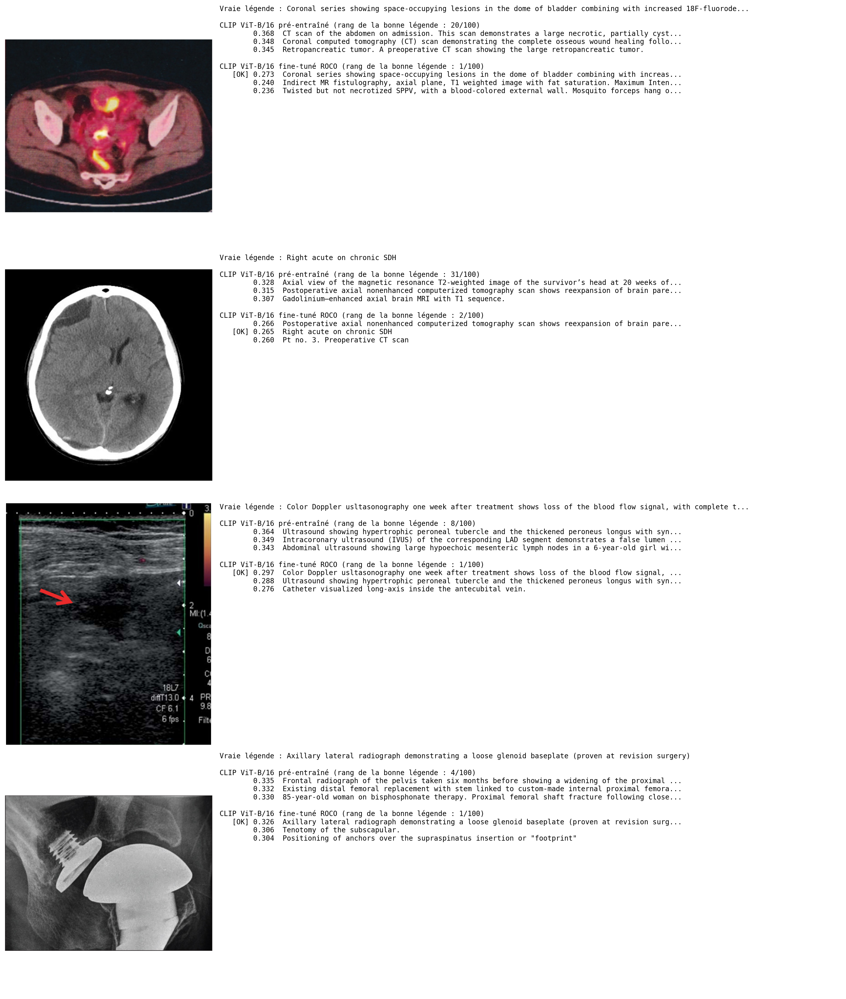

In [ ]:
import textwrap

# Retrieval sur 100 légendes du test en gros on veut savoir pour chaque image, quelles légendes CLIP choisit-il ?
POOL_SIZE = 100
pool_idx = np.concatenate([q3_idx, rng.choice(np.setdiff1d(np.arange(len(cached_captions)), q3_idx),
                                              size=POOL_SIZE - len(q3_idx), replace=False)])
pool_texts = [cached_captions[i].replace("\n", " ").strip() for i in pool_idx]

pool_sims = {}
for name, m in q3_models.items():
    sim = similarity_matrix(m, pool_idx, pool_texts).T          # (images, textes)
    ranks = (sim > sim[np.arange(POOL_SIZE), np.arange(POOL_SIZE)][:, None]).sum(axis=1) + 1
    pool_sims[name] = sim
    print(f"{name} (pool de {POOL_SIZE}) : top-1 = {np.mean(ranks == 1) * 100:.1f} %, "
          f"top-5 = {np.mean(ranks <= 5) * 100:.1f} %, rang médian de la bonne légende = {int(np.median(ranks))}")

N_EXAMPLES = 4
fig, axes = plt.subplots(N_EXAMPLES, 2, figsize=(18, 5 * N_EXAMPLES), gridspec_kw={"width_ratios": [1, 3]})
for row in range(N_EXAMPLES):
    axes[row, 0].imshow(q3_display[row])
    axes[row, 0].axis("off")
    lines = ["Vraie légende : " + short_caption(pool_texts[row], 110), ""]
    for name, sim in pool_sims.items():
        order = np.argsort(-sim[row])
        rank = int(np.where(order == row)[0][0]) + 1
        lines.append(f"{name} (rang de la bonne légende : {rank}/{POOL_SIZE})")
        for k in order[:3]:
            mark = "[OK] " if k == row else "     "
            lines.append(f"   {mark}{sim[row, k]:.3f}  " + short_caption(pool_texts[k], 95))
        lines.append("")
    axes[row, 1].axis("off")
    axes[row, 1].text(0, 1, "\n".join(lines), va="top", family="monospace", fontsize=10)
plt.tight_layout()
plt.show()

# Question 4 : Calculer les performance clip sur des données naturelle d'un autre jeu de données  'Oxford-IIIT pets'

In [ ]:
from torch.utils.data import DataLoader
from torchvision.datasets import OxfordIIITPet

oxfordiiit_pet = OxfordIIITPet(os.path.expanduser("~/.cache"), transform=preprocess, download=True, split="test")

100%|██████████| 792M/792M [00:38<00:00, 20.6MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.1MB/s]


In [ ]:
prompts = {}
for classe in oxfordiiit_pet.classes:
  prompts[classe] = f"an image of {classe}"

prompts

{'Abyssinian': 'an image of Abyssinian',
 'American Bulldog': 'an image of American Bulldog',
 'American Pit Bull Terrier': 'an image of American Pit Bull Terrier',
 'Basset Hound': 'an image of Basset Hound',
 'Beagle': 'an image of Beagle',
 'Bengal': 'an image of Bengal',
 'Birman': 'an image of Birman',
 'Bombay': 'an image of Bombay',
 'Boxer': 'an image of Boxer',
 'British Shorthair': 'an image of British Shorthair',
 'Chihuahua': 'an image of Chihuahua',
 'Egyptian Mau': 'an image of Egyptian Mau',
 'English Cocker Spaniel': 'an image of English Cocker Spaniel',
 'English Setter': 'an image of English Setter',
 'German Shorthaired': 'an image of German Shorthaired',
 'Great Pyrenees': 'an image of Great Pyrenees',
 'Havanese': 'an image of Havanese',
 'Japanese Chin': 'an image of Japanese Chin',
 'Keeshond': 'an image of Keeshond',
 'Leonberger': 'an image of Leonberger',
 'Maine Coon': 'an image of Maine Coon',
 'Miniature Pinscher': 'an image of Miniature Pinscher',
 'Newfou

In [ ]:
zero_shot_data = DataLoader(oxfordiiit_pet, batch_size=64, shuffle=False, num_workers=2)
zero_shot_data

In [ ]:
model_b16.eval()
top1_results = 0
top5_results = 0
nbr_iter = 0


token_prompts = clip.tokenize(list(prompts.values())).to("cuda")
vect_prompts = model_b16.encode_text(token_prompts)
vect_prompts /= vect_prompts.norm(dim=-1, keepdim=True)

with torch.inference_mode():
  for images, labels in zero_shot_data:
    images = images.to("cuda")
    labels = labels.to("cuda")

    # encodage des images
    image_features = model_b16.encode_image(images)
    image_features /= image_features.norm(dim=-1, keepdim=True)

    # calcul de la similarité
    similarity = image_features @ vect_prompts.T

    # resultats
    results = similarity.argmax(dim=1)
    top1_results += (results == labels).sum().item()

    # top 5 accuracy
    results_top5 = similarity.topk(5, dim=1).indices
    top5_results += (results_top5 == labels.unsqueeze(1)).any(dim=1).sum().item()

    # utilisé apres pour le calcule de l'accuracy
    nbr_iter += labels.size(0)

print(f"top1 accuracy est : {100 * top1_results/nbr_iter}")
print(f"top5 accuracy est : {100 * top5_results/nbr_iter}")



top1 accuracy est : 80.23984736985555
top5 accuracy est : 91.4418097574271


In [ ]:
from torchvision.datasets import CIFAR100

cifar100_test = CIFAR100(os.path.expanduser("~/.cache"), transform=preprocess, download=True, train=False)
cifar_loader = DataLoader(cifar100_test, batch_size=256, shuffle=False, num_workers=2)

with torch.inference_mode():
    cifar_tokens = clip.tokenize([f"an image of {c}" for c in cifar100_test.classes]).to("cuda")
    cifar_text = model_b16.encode_text(cifar_tokens)
    cifar_text /= cifar_text.norm(dim=-1, keepdim=True)

    c_top1, c_top5, c_total = 0, 0, 0
    for images, labels in cifar_loader:
        images, labels = images.to("cuda"), labels.to("cuda")
        feats = model_b16.encode_image(images)
        feats /= feats.norm(dim=-1, keepdim=True)
        sim = feats @ cifar_text.T
        c_top1 += (sim.argmax(dim=1) == labels).sum().item()
        c_top5 += (sim.topk(5, dim=1).indices == labels.unsqueeze(1)).any(dim=1).sum().item()
        c_total += labels.size(0)

print(f"CIFAR-100 test : top1 = {100 * c_top1 / c_total:.2f} %, top5 = {100 * c_top5 / c_total:.2f} %")

CIFAR-100 test : top1 = 62.76 %, top5 = 85.53 %
